# Data Visualization with Matplotlib and Seaborn
**GDG on Campus | COMSATS University, Attock Campus: AI/ML Team, Month 2, Week 1**

**Name:** Ayesha  |  **Roll No:** FA23-BSE-032

This notebook has all 14 tasks (7 Matplotlib + 7 Seaborn). Every plot is followed by a short written insight.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

# Load every dataset once, up front
tips     = sns.load_dataset("tips")
flights  = sns.load_dataset("flights")
mpg      = sns.load_dataset("mpg")
penguins = sns.load_dataset("penguins")
titanic  = sns.load_dataset("titanic")

print("Datasets loaded:", tips.shape, flights.shape, mpg.shape, penguins.shape, titanic.shape)

Matplotlib is building the font cache; this may take a moment.


ModuleNotFoundError: No module named 'seaborn'

# Part 1: Matplotlib Tasks

## Task 1: Line plot (flights)
Monthly passengers for one year (1960).

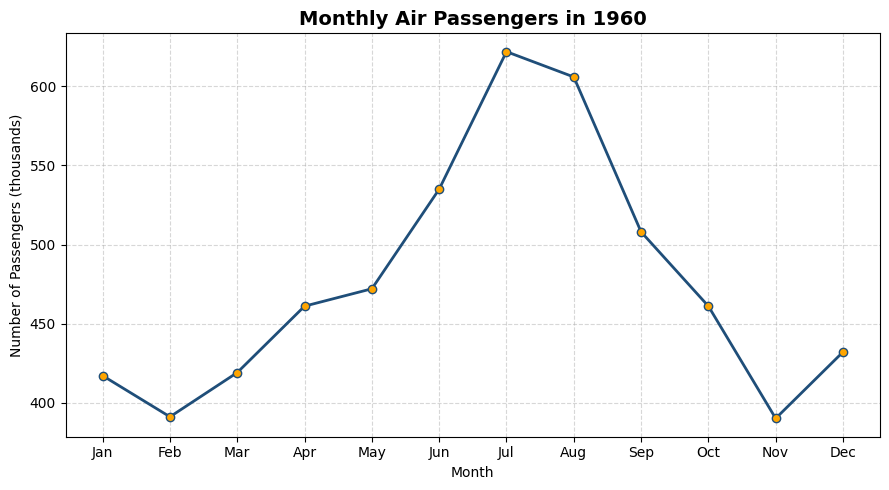

In [ ]:
f1960 = flights[flights["year"] == 1960]

plt.figure(figsize=(9, 5))
plt.plot(f1960["month"].astype(str), f1960["passengers"],
         marker="o", linewidth=2, color="#1f4e79", markerfacecolor="orange")
plt.title("Monthly Air Passengers in 1960", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Number of Passengers (thousands)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:** Passenger numbers climb steadily from January and peak in July at 622, then fall back to about 390 by November. This points to a clear summer travel season, with a smaller bump again in December.

## Task 2: Bar chart (tips)
Average `total_bill` by day, with value labels and custom colors.

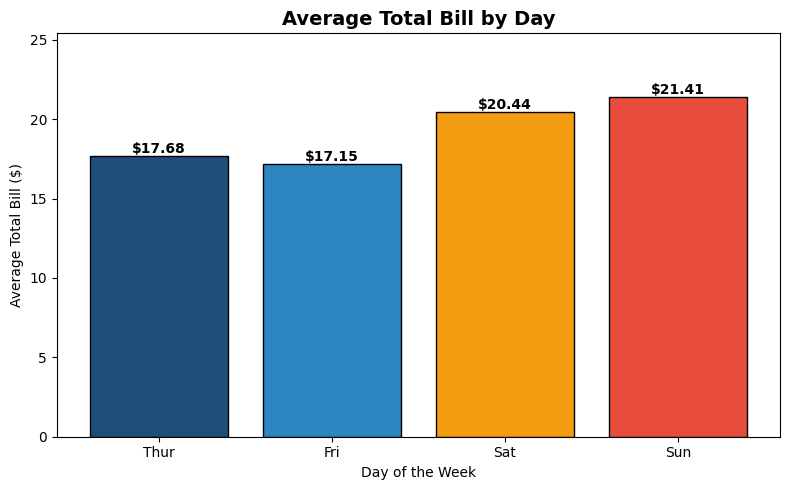

In [ ]:
avg_day = tips.groupby("day", observed=True)["total_bill"].mean()

plt.figure(figsize=(8, 5))
bars = plt.bar(avg_day.index.astype(str), avg_day.values,
               color=["#1f4e79", "#2e86c1", "#f39c12", "#e74c3c"], edgecolor="black")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
             f"${bar.get_height():.2f}", ha="center", fontweight="bold")
plt.title("Average Total Bill by Day", fontsize=14, fontweight="bold")
plt.xlabel("Day of the Week")
plt.ylabel("Average Total Bill ($)")
plt.ylim(0, avg_day.max() + 4)
plt.tight_layout()
plt.show()

**Insight:** Weekend bills are clearly higher. Sunday averages about $21.41 and Saturday about $20.44, while Thursday and Friday stay close to $17. People seem to spend more when they dine out on the weekend.

## Task 3: Horizontal bar chart (mpg)
Average mpg by number of cylinders, sorted from highest to lowest.

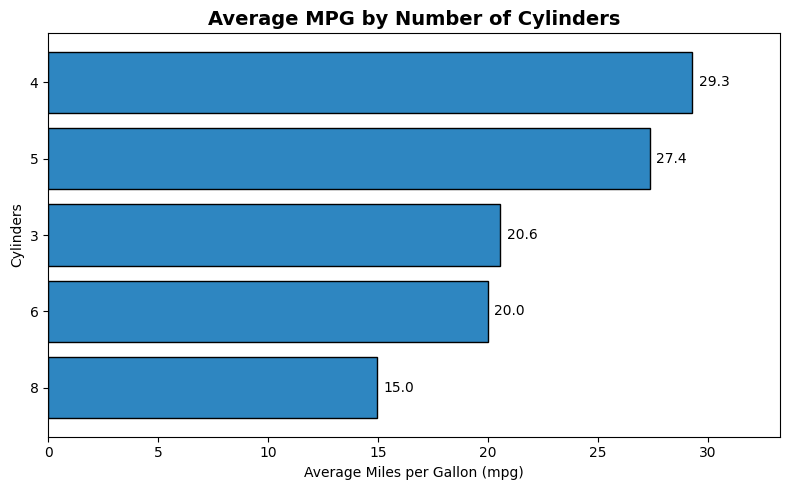

In [ ]:
avg_cyl = mpg.groupby("cylinders")["mpg"].mean().sort_values(ascending=True)  # ascending so the highest ends up on top

plt.figure(figsize=(8, 5))
bars = plt.barh(avg_cyl.index.astype(str), avg_cyl.values, color="#2e86c1", edgecolor="black")
for bar in bars:
    plt.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():.1f}", va="center")
plt.title("Average MPG by Number of Cylinders", fontsize=14, fontweight="bold")
plt.xlabel("Average Miles per Gallon (mpg)")
plt.ylabel("Cylinders")
plt.xlim(0, avg_cyl.max() + 4)
plt.tight_layout()
plt.show()

**Insight:** 4-cylinder cars are the most fuel efficient at about 29 mpg, and 8-cylinder cars are the least at about 15 mpg. The 3-cylinder group sits in the middle, but there are only a handful of those cars, so I would not read too much into it.

## Task 4: Histogram (tips)
`total_bill` with 3 different bin sizes side by side, with vertical lines for the mean and median.

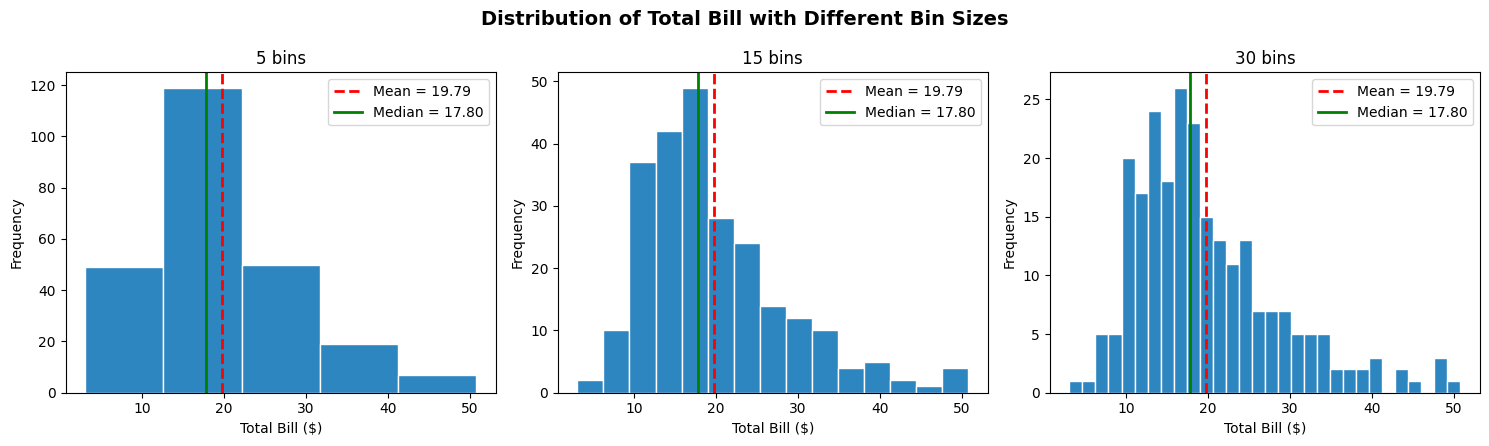

In [ ]:
mean_bill   = tips["total_bill"].mean()
median_bill = tips["total_bill"].median()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
for ax, bins in zip(axes, [5, 15, 30]):
    ax.hist(tips["total_bill"], bins=bins, color="#2e86c1", edgecolor="white")
    ax.axvline(mean_bill, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_bill:.2f}")
    ax.axvline(median_bill, color="green", linestyle="-", linewidth=2, label=f"Median = {median_bill:.2f}")
    ax.set_title(f"{bins} bins")
    ax.set_xlabel("Total Bill ($)")
    ax.set_ylabel("Frequency")
    ax.legend()
fig.suptitle("Distribution of Total Bill with Different Bin Sizes", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:** Most bills fall between $10 and $20, with a long tail of bigger bills on the right. The mean (about $19.79) sits above the median (about $17.80), which tells us the distribution is right-skewed. Too few bins hide this shape, and too many make it look noisy.

## Task 5: Scatter plot (mpg)
Weight vs mpg, color by origin, point size by horsepower.

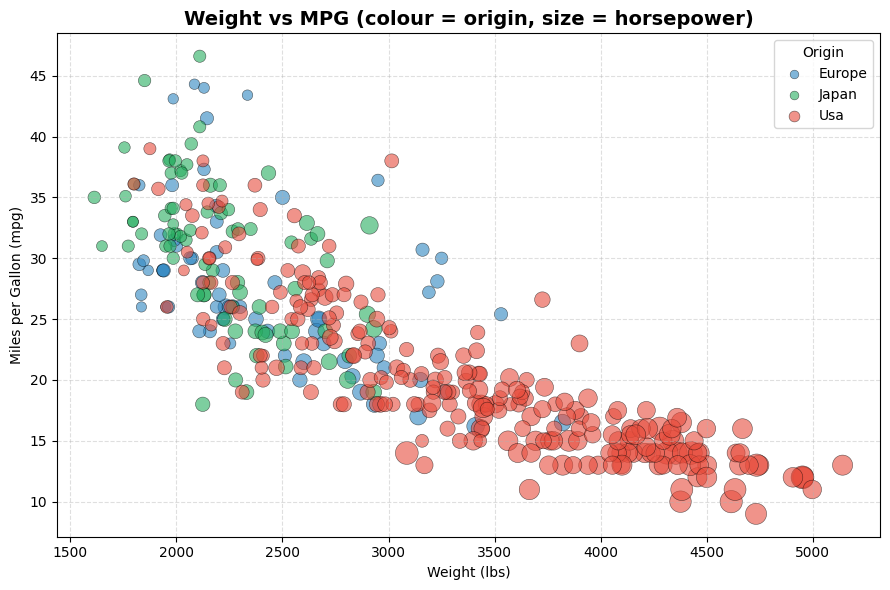

In [ ]:
m = mpg.dropna(subset=["horsepower"])
colors = {"usa": "#e74c3c", "europe": "#2e86c1", "japan": "#27ae60"}

plt.figure(figsize=(9, 6))
for origin, grp in m.groupby("origin"):
    plt.scatter(grp["weight"], grp["mpg"], s=grp["horsepower"] * 1.2,
                color=colors[origin], alpha=0.6, edgecolor="black", linewidth=0.4, label=origin.title())
plt.title("Weight vs MPG (colour = origin, size = horsepower)", fontsize=14, fontweight="bold")
plt.xlabel("Weight (lbs)")
plt.ylabel("Miles per Gallon (mpg)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Origin", markerscale=0.6)
plt.tight_layout()
plt.show()

**Insight:** Heavier cars get fewer miles per gallon, and the relationship is strong (correlation of about -0.83). The big bubbles (high horsepower) are mostly American cars in the heavy, low-mpg corner, while Japanese and European cars are lighter and more efficient.

## Task 6: Donut chart (tips)
Smoker vs non-smoker share.

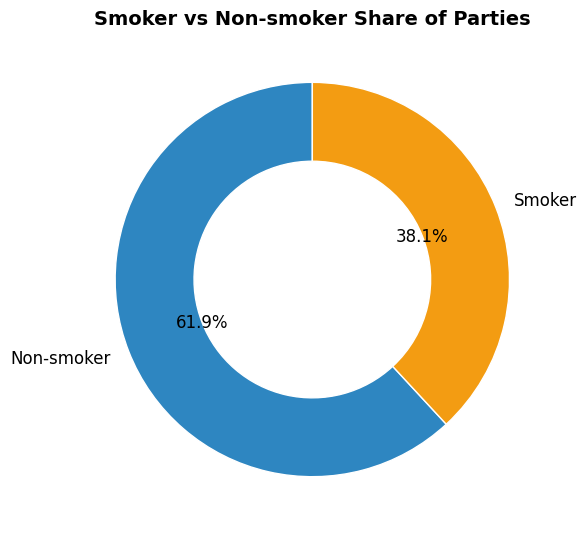

In [ ]:
counts = tips["smoker"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(counts.values, labels=["Non-smoker" if i == "No" else "Smoker" for i in counts.index],
        autopct="%1.1f%%", startangle=90, colors=["#2e86c1", "#f39c12"],
        wedgeprops={"width": 0.4, "edgecolor": "white"}, textprops={"fontsize": 12})
plt.title("Smoker vs Non-smoker Share of Parties", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:** About 62% of the parties in the dataset were non-smokers (151 out of 244) and about 38% were smokers (93). Non-smokers are the clear majority, but smokers are still a big enough group to compare against.

## Task 7: Mini dashboard (2 x 2)
Four of the plots above combined in one figure, saved as a PNG at `dpi=300`.

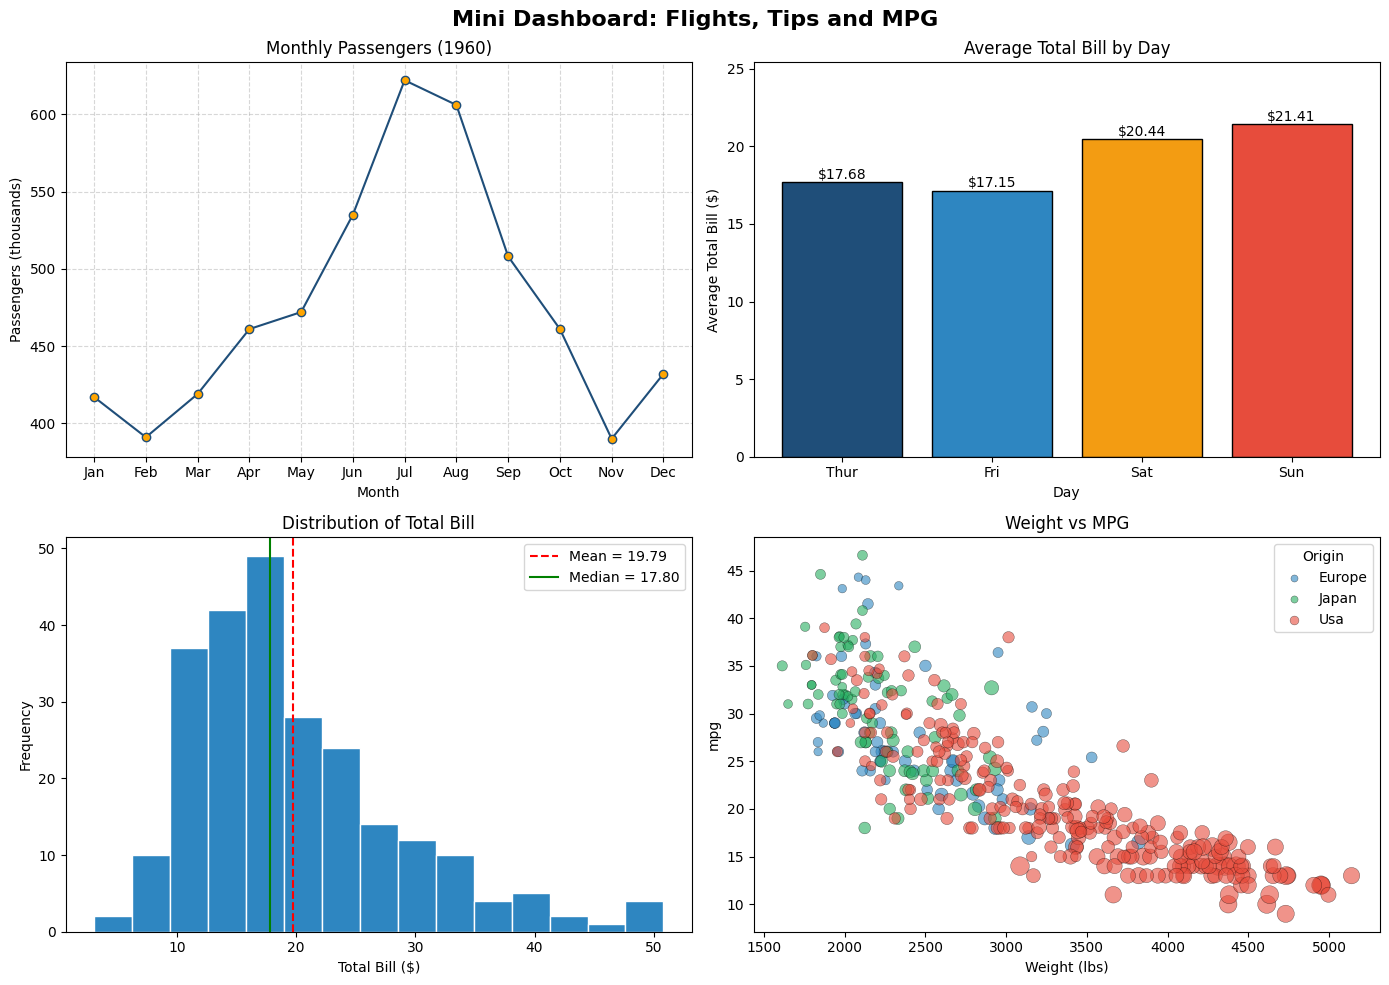

Saved: matplotlib_dashboard.png (dpi=300)


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top-left: line plot (flights)
axes[0, 0].plot(f1960["month"].astype(str), f1960["passengers"], marker="o", color="#1f4e79", markerfacecolor="orange")
axes[0, 0].set_title("Monthly Passengers (1960)")
axes[0, 0].set_xlabel("Month"); axes[0, 0].set_ylabel("Passengers (thousands)")
axes[0, 0].grid(True, linestyle="--", alpha=0.5)

# Top-right: bar chart (tips)
b = axes[0, 1].bar(avg_day.index.astype(str), avg_day.values, color=["#1f4e79", "#2e86c1", "#f39c12", "#e74c3c"], edgecolor="black")
for bar in b:
    axes[0, 1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2, f"${bar.get_height():.2f}", ha="center")
axes[0, 1].set_title("Average Total Bill by Day")
axes[0, 1].set_xlabel("Day"); axes[0, 1].set_ylabel("Average Total Bill ($)")
axes[0, 1].set_ylim(0, avg_day.max() + 4)

# Bottom-left: histogram (tips)
axes[1, 0].hist(tips["total_bill"], bins=15, color="#2e86c1", edgecolor="white")
axes[1, 0].axvline(mean_bill, color="red", linestyle="--", label=f"Mean = {mean_bill:.2f}")
axes[1, 0].axvline(median_bill, color="green", label=f"Median = {median_bill:.2f}")
axes[1, 0].set_title("Distribution of Total Bill")
axes[1, 0].set_xlabel("Total Bill ($)"); axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()

# Bottom-right: scatter plot (mpg)
for origin, grp in m.groupby("origin"):
    axes[1, 1].scatter(grp["weight"], grp["mpg"], s=grp["horsepower"] * 0.8, color=colors[origin],
                       alpha=0.6, edgecolor="black", linewidth=0.3, label=origin.title())
axes[1, 1].set_title("Weight vs MPG")
axes[1, 1].set_xlabel("Weight (lbs)"); axes[1, 1].set_ylabel("mpg")
axes[1, 1].legend(title="Origin", markerscale=0.6)

fig.suptitle("Mini Dashboard: Flights, Tips and MPG", fontsize=16, fontweight="bold")
plt.tight_layout()
fig.savefig("matplotlib_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved: matplotlib_dashboard.png (dpi=300)")

**Insight:** Putting the four views together makes the story easy to scan: air travel peaks in summer, weekends bring bigger restaurant bills, bills are right-skewed, and heavier cars burn more fuel. A dashboard like this is a quick way to compare different datasets at a glance.

# Part 2: Seaborn Tasks

In [ ]:
# Custom theme for the Seaborn section (also required by Task 7)
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.1,
              rc={"axes.edgecolor": "#444444", "grid.linestyle": "--", "figure.dpi": 100})

## Task 1: Countplot (titanic)
Passengers by class, with `hue` set to sex.

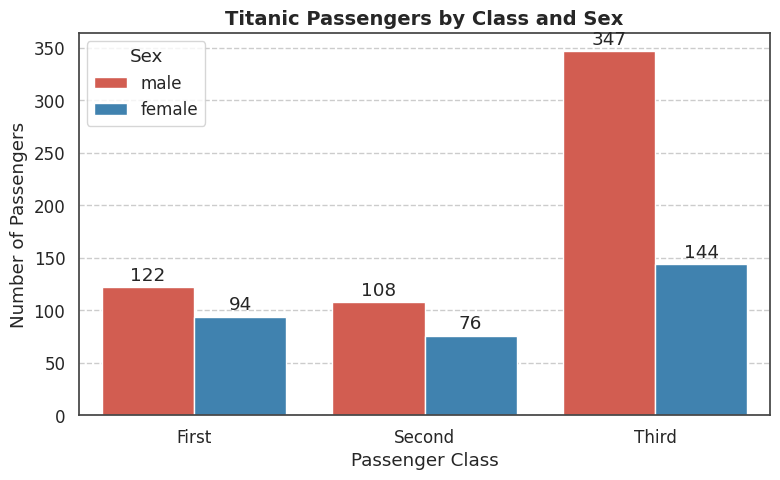

In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=titanic, x="class", hue="sex", palette=["#e74c3c", "#2e86c1"])
for c in ax.containers:
    ax.bar_label(c, padding=2)
plt.title("Titanic Passengers by Class and Sex", fontsize=14, fontweight="bold")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Sex")
plt.tight_layout()
plt.show()

**Insight:** Third class carried by far the most passengers (491), and it is also where the gap between men and women is biggest, with 347 men against 144 women. In first and second class the numbers are much closer.

## Task 2: Histogram with KDE (penguins)
`flipper_length_mm` for each species using `histplot(kde=True)`.

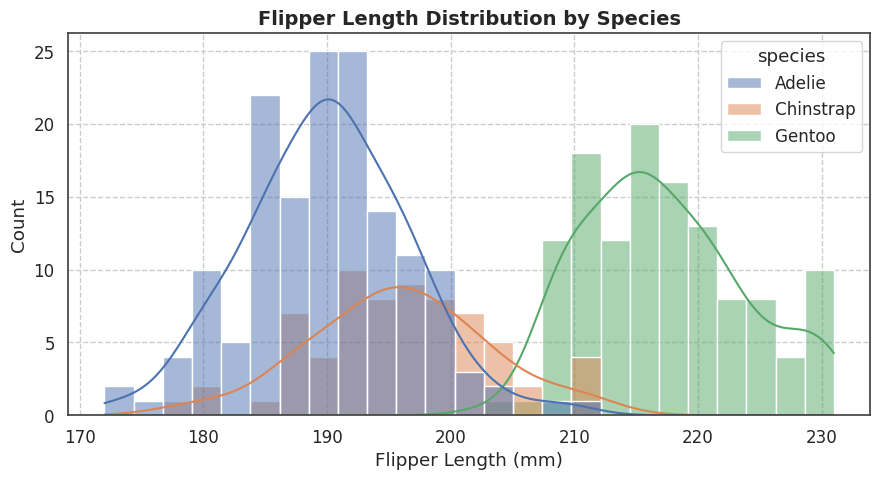

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(data=penguins, x="flipper_length_mm", hue="species", kde=True, bins=25, alpha=0.5)
plt.title("Flipper Length Distribution by Species", fontsize=14, fontweight="bold")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

**Insight:** Gentoo penguins have the longest flippers (about 217 mm on average) and sit clearly apart from the others. Adelie (about 190 mm) and Chinstrap (about 196 mm) overlap a lot, so flipper length alone cannot separate those two well.

## Task 3: Box vs violin (penguins)
`body_mass_g` by species, with both plot types side by side.

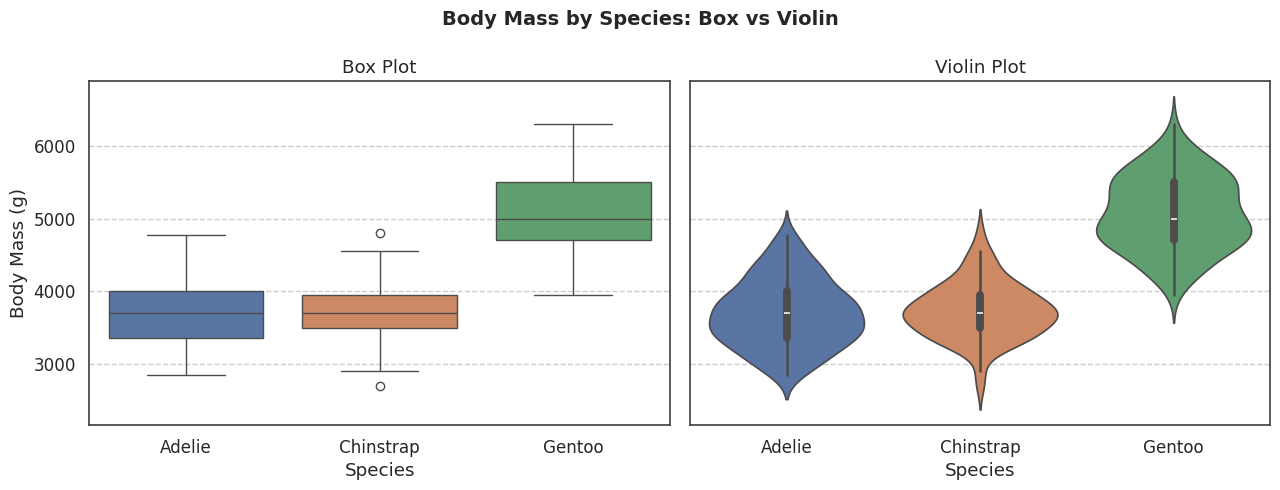

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
sns.boxplot(data=penguins, x="species", y="body_mass_g", hue="species", ax=axes[0], legend=False)
axes[0].set_title("Box Plot")
axes[0].set_xlabel("Species"); axes[0].set_ylabel("Body Mass (g)")
sns.violinplot(data=penguins, x="species", y="body_mass_g", hue="species", ax=axes[1], legend=False)
axes[1].set_title("Violin Plot")
axes[1].set_xlabel("Species"); axes[1].set_ylabel("")
fig.suptitle("Body Mass by Species: Box vs Violin", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight (box vs violin):** The box plot gives a clean summary of the median, the quartiles and any outliers, so it is good for quick comparisons. The violin plot shows more, because it also reveals the full shape of the distribution (where values bunch up and whether there is more than one peak), which a box can hide. Either way, Gentoo penguins are clearly the heaviest (about 5,076 g on average against about 3,700 g for the other two).

## Task 4: Scatterplot (penguins)
`bill_length_mm` vs `bill_depth_mm` with `hue=species` and `style=sex`.

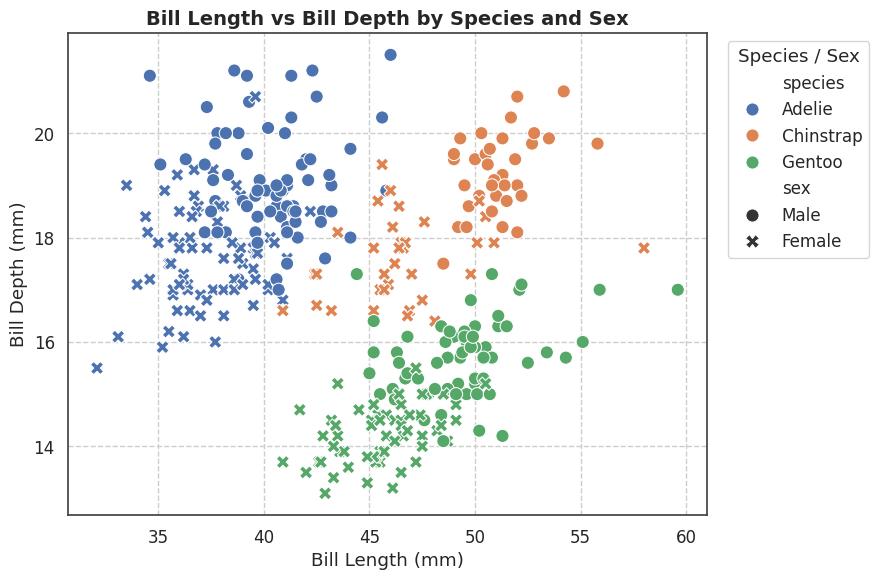

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=penguins, x="bill_length_mm", y="bill_depth_mm",
                hue="species", style="sex", s=90)
plt.title("Bill Length vs Bill Depth by Species and Sex", fontsize=14, fontweight="bold")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Species / Sex")
plt.tight_layout()
plt.show()

**Insight:** The three species form separate clusters: Adelie have short, deep bills, Chinstrap have long, deep bills, and Gentoo have long, shallow bills. Within each species the males sit towards the upper right, so males tend to have bigger bills than females.

## Task 5: Heatmap (penguins)
Correlation matrix of the numeric columns with `annot=True` and a diverging colormap.

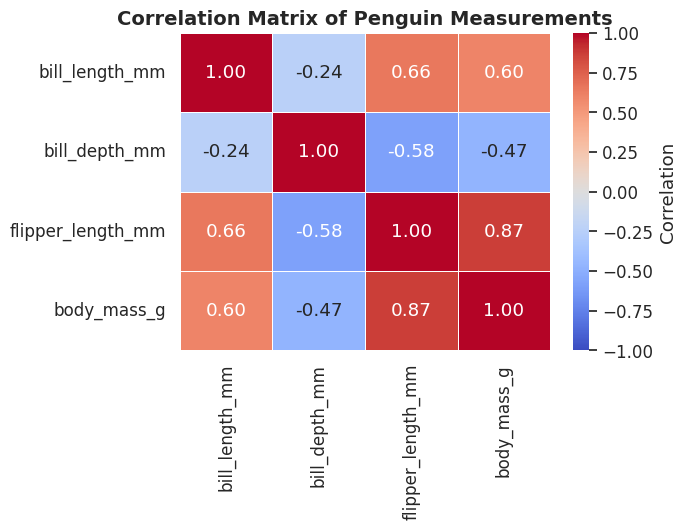

In [ ]:
corr = penguins.select_dtypes(include="number").corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Correlation"})
plt.title("Correlation Matrix of Penguin Measurements", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:** Flipper length and body mass have the strongest link (0.87), which makes sense because bigger birds have bigger flippers. Bill depth is negatively related to the other measurements (for example -0.58 with flipper length), which looks odd until you remember that it is partly caused by mixing three species together.

## Task 6: Pairplot (penguins)
`pairplot` with `hue=species`, followed by 3 insights.

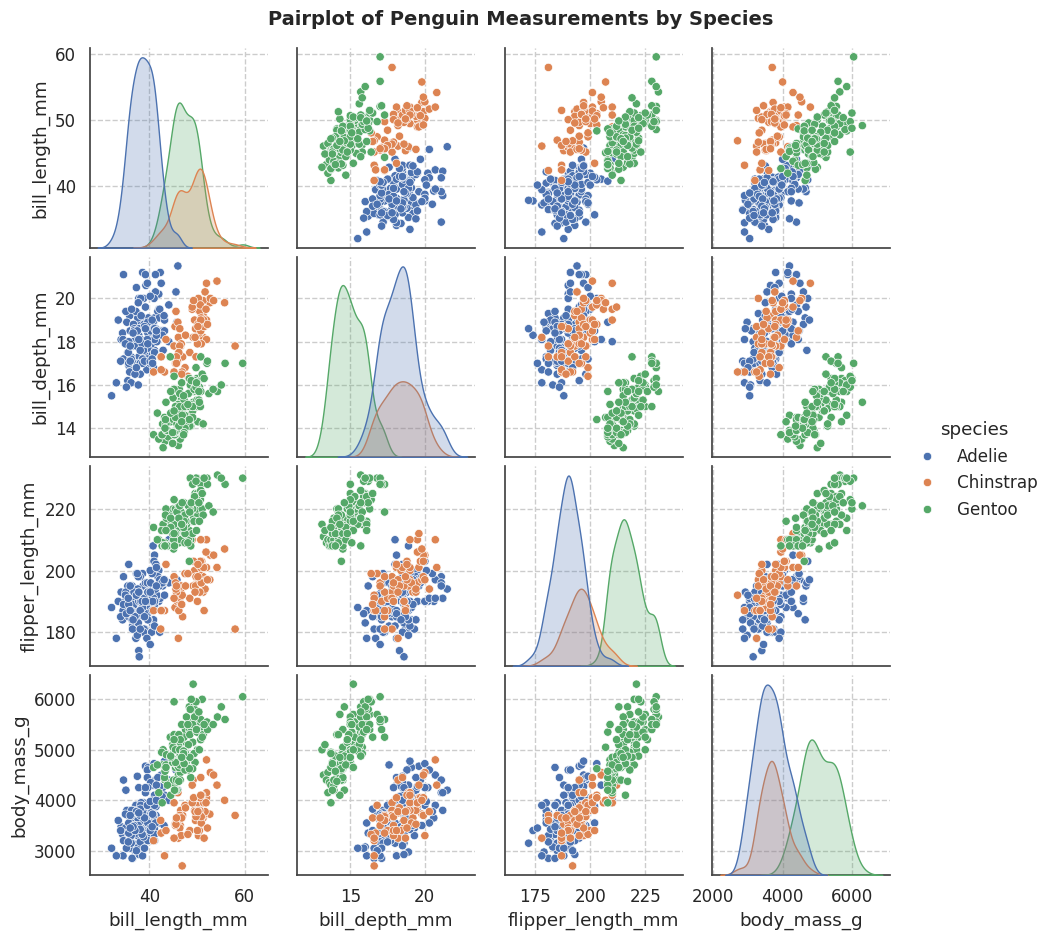

In [ ]:
g = sns.pairplot(penguins, hue="species", corner=False, diag_kind="kde", height=2.3)
g.figure.suptitle("Pairplot of Penguin Measurements by Species", y=1.02, fontsize=14, fontweight="bold")
plt.show()

**Insights from the pairplot:**
1. **Gentoo stands out in almost every panel.** It has the longest flippers and the highest body mass, so it separates cleanly from the other two species.
2. **Adelie and Chinstrap overlap in body mass and flipper length** but separate on bill length, where Chinstrap's bills are noticeably longer.
3. **Bill depth vs flipper length looks negative overall, but inside each species the trend is flat or positive.** The overall negative trend comes from mixing species (Gentoo has long flippers but shallow bills), so the species split changes the story.

## Task 7: lmplot / FacetGrid (tips)
`total_bill` vs `tip` with a regression line, split by `time` and `smoker`, using a custom `sns.set_theme()`.

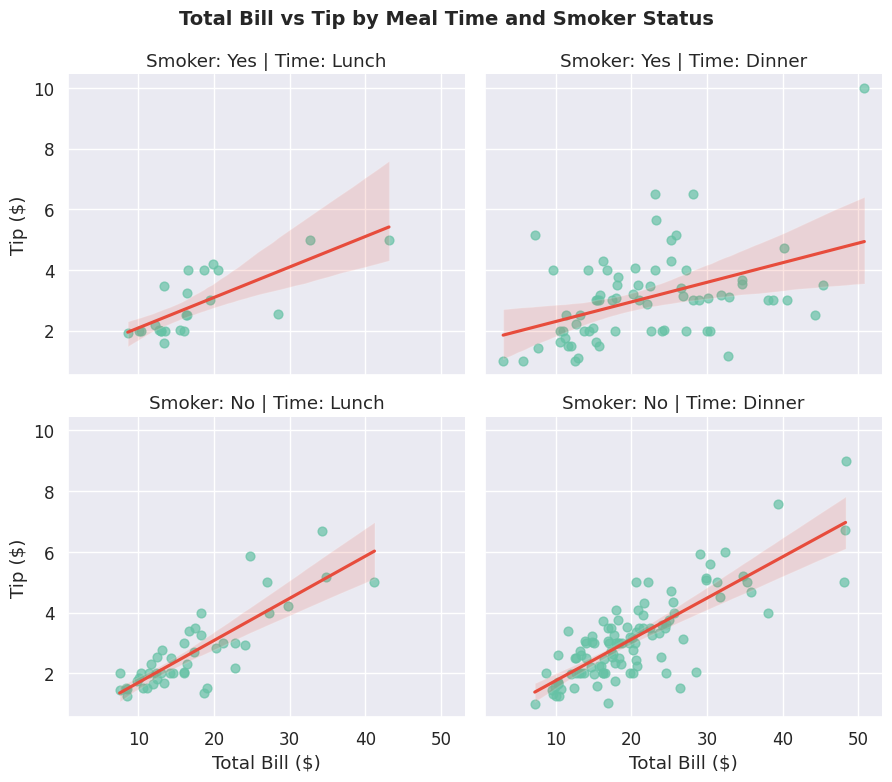

In [ ]:
sns.set_theme(style="darkgrid", palette="Set2", font_scale=1.1)

g = sns.lmplot(data=tips, x="total_bill", y="tip", col="time", row="smoker",
               height=3.8, aspect=1.2, scatter_kws={"alpha": 0.7, "s": 40},
               line_kws={"color": "#e74c3c"})
g.set_axis_labels("Total Bill ($)", "Tip ($)")
g.set_titles("Smoker: {row_name} | Time: {col_name}")
g.figure.suptitle("Total Bill vs Tip by Meal Time and Smoker Status", y=1.03, fontsize=14, fontweight="bold")
plt.show()

**Insight:** In every panel, bigger bills lead to bigger tips, so the positive relationship holds no matter the time or smoker status. The smoker lines look flatter, especially at dinner, which suggests tips from smokers depend less on the bill size. The lunch smoker panel has only 23 points, so that line is the least reliable.

---
**End of notebook.** All 14 tasks are completed in the order given in the task sheet.